# Un réseau 315 kV du Québec qui converge en AC — avec un réactif réaliste

**Capstone ECSE 458 · Jean Flichy · 16-17 novembre 2026**
Construit par Claude (conversation claude.ai, travail autonome pendant la nuit) à partir du modèle PyPSA-Earth de Nathan Guan et du travail d'Etienne. **Tout est à relire et à refaire étape par étape avec Claude Code** avant d'être présenté comme le travail de l'équipe (et à déclarer comme usage d'IA dans les livrables, cf. plan de cours).

---

### Le résultat en une phrase

Sur la semaine test du 1er au 7 janvier 2022 (168 h, pointe 35,0 GW), le réseau 315 kV **converge 168/168 heures en AC power flow avec les limites de réactif de tous les générateurs, SVC et compensateurs synchrones**, les tensions restent **dans 0,90-1,10 pu à toutes les heures et dans la bande d'exploitation 0,95-1,05 pu à 165/168 heures** (0,922 à 1,035 pu ; les 3 exceptions sont les heures les plus chargées, à Montréal-Ouest), le LOPF ne déleste rien, et **trois solveurs indépendants** (un Newton-Raphson maison, celui de PyPSA, celui de pandapower) donnent la même solution à 10⁻⁷ pu près. **La limite principale** : à la pointe, le cas de base n'a **pas de marge de charge** (moins de +0,5 % avant l'effondrement de tension, §11.2), parce que le sud manque de réactif ; c'est à régler (avec des données HQ) avant les cascades.

| | Etienne (14 nov.) | **Ce notebook** |
|---|---|---|
| Heures convergées | 161-162 / 168 | **168 / 168** |
| Heures dans 0,90-1,10 pu | 0 | **168** |
| Heures dans 0,95-1,05 pu | 0 | **165** |
| Tensions | 0,91 - 1,62 pu | **0,922 - 1,035 pu** |
| Réactif des générateurs | illimité (une centrale de 302 MW absorbait 13,5 GVAr) | **borné** (bascule PV → PQ) |
| Inductances enclenchées à la pointe | — | **13 GVAr** (HQ : ~11 GVAr) |
| Marge de charge à la pointe | — | **< +0,5 %** (le vrai réseau : +23 % au moins) |

### Ce qui a changé, en sept étapes

| Étape | Quoi | Pourquoi (en bref) |
|---|---|---|
| **E1** | Longueurs des lignes recalculées sur leur tracé réel | PyPSA-Earth les mesure en **Web Mercator** : +41 à +66 % selon la latitude, donc x et b trop grands |
| **E2** | Churchill Falls : 3 circuits au lieu de 6 | le poste était coupé en deux bus, avec les 3 lignes en double |
| **E2b** | Équivalents de Kron du réseau < 315 kV (Saguenay, Montréal) | la réduction a supprimé les chemins < 315 kV et la transformation de 20 postes 735 kV : une poche de 1 GW pendait à une seule ligne, et Montréal-Ouest descendait à 0,89 pu |
| **E3** | Circuits des corridors de départ | script de Nathan, inchangé |
| **E4** | Compensation série **40 %** sur les corridors réels d'HQ | au lieu de 70 % générique (HQ : 35-40 % par plateforme) |
| **E5** | LOPF relancé sur le réseau corrigé, avec une **limite de stabilité** | la ligne de la Romaine transitait 90 % de V²/x |
| **E6** | Réactif réaliste : régulateurs à limites Q, **SVC et compensateurs synchrones réels d'HQ**, inductances de ligne et condensateurs **commutables**, consigne 1,02 pu | c'est ce qui manquait pour converger *sans tricher* |
| **E7** | Résolution heure par heure : Newton-Raphson + limites Q + manœuvre des shunts comme un exploitant d'HQ | les shunts sont manœuvrés pour garder de la réserve dans les SVC |

### Comment lire ce notebook
Chaque étape : **la physique** (courte, avec les équations), **la preuve** dans les données, **la correction**, **son effet**. Les §10 à §13 présentent les résultats, la validation, les alternatives de conception (une hypothèse retirée à la fois) et, surtout, **les limites** : ce qui reste faux ou supposé.

### Comment le relancer (venv `pypsa-env`, PyPSA 1.3.0)
```
cd quebec-pypsa-earth
pypsa-env\Scripts\python.exe -m pip install matplotlib pandapower   (pandapower : optionnel, 3e solveur)
pypsa-env\Scripts\python.exe Jean_tests\convergence_315kv\reseau_315kv\construire.py --valider   (≈ 10 min)
```
puis ouvrir ce notebook dans le même dossier. Sans `construire.py`, le notebook recalcule lui-même le cas final (≈ 3 min) mais pas la validation complète.

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
HERE = os.path.abspath(".")
sys.path.insert(0, HERE)
import reseau315 as R
OUT = os.path.join(HERE, "resultats"); FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
PEAK, NIGHT = pd.Timestamp("2022-01-03 17:00"), pd.Timestamp("2022-01-01 03:00")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
mpl.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
def savefig(name): plt.savefig(os.path.join(FIG, name), bbox_inches="tight")
import pypsa; print("PyPSA", pypsa.__version__, "| pandas", pd.__version__, "| dépôt :", R.REPO)

PyPSA 1.3.0 | pandas 2.3.3 | dépôt : /home/claude/quebec-pypsa-earth


## 1. Le point de départ

Le modèle de Nathan a trois niveaux : `elec_full.nc` (tout l'OSM, ~4 000 bus) → `elec_solved.nc` (**réseau 315 kV**, ~205 bus, LOPF résolu) → `elec_735kv.nc` (58 bus). La Prof. Wang a demandé (17 sept., confirmé le 3 nov.) un réseau **plus bas que le 735 kV** qui converge **en LOPF et en AC**. Le 315 kV convergé est l'objectif.

Etienne (11-14 nov.) a appliqué au 315 kV les corrections de Nathan pour le 735 kV (circuits, compensation série 70 % sur 19 lignes, shunts) : **161/168 h**. Claude Code a reproduit ce résultat le 16 nov. (162/168 en PyPSA 1.3) et montré que **0 heure n'est acceptable en tension** (0,91 à 1,62 pu), et que la convergence reposait sur un **réactif illimité** : PyPSA n'impose aucune limite Q en power flow, donc une centrale au fil de l'eau de 302 MW pouvait absorber 13,5 GVAr.

### Ce qu'on appelle « convergé » ici
Trois conditions, à chaque heure : (1) Newton-Raphson converge (résidu < 10⁻³ MW/MVAr) ; (2) **toutes** les tensions dans 0,90-1,10 pu (cible d'exploitation : 0,95-1,05) ; (3) **chaque** source de réactif reste dans ses limites. La condition (3) est la plus exigeante : c'est elle qui transforme un « calcul qui tombe juste » en « réseau qui pourrait exister ».

In [2]:
# référence : la séquence d'Etienne reproduite par Claude Code (fichier de results/ du 16 nov.), recalculée ici
ref = os.path.join(HERE, "..", "results", "elec_315kv_shunt.nc")
V_etienne = None
if os.path.exists(ref):
    ne = R.load(ref)
    with R.quiet():
        R.run_pf.use_lopf_dispatch_as_setpoints(ne); ne.determine_network_topology()
        R.run_pf.prepare_for_ac_pf(ne, pv_min_capacity=0.0, pv_max_load_ratio=1.0)
        ne.lpf(); res = ne.pf(use_seed=True)
    conv_e = res.converged.all(axis=1)
    ac = ne.buses.index[ne.buses.carrier == "AC"]
    V_etienne = ne.buses_t.v_mag_pu.loc[conv_e, ac]
    g = ne.generators[ne.generators.control.isin(["PV", "Slack"]) & (ne.generators.carrier != "load_shedding")]
    qr = (ne.generators_t.q.loc[conv_e, g.index].abs().max() / g.p_nom.replace(0, np.nan)).sort_values(ascending=False)
    print(f"Etienne (reproduit) : {int(conv_e.sum())}/168 convergées | V {V_etienne.min().min():.3f}-{V_etienne.max().max():.3f} pu | "
          f"heures dans 0,90-1,10 : {int(((V_etienne >= 0.9) & (V_etienne <= 1.1)).all(axis=1).sum())}")
    print("Réactif demandé aux régulateurs, en multiple de leur puissance (|Q| max / p_nom) :")
    print(qr.head(5).round(1).to_string())
else:
    print("Fichier de référence d'Etienne absent :", ref)

Etienne (reproduit) : 162/168 convergées | V 0.910-1.615 pu | heures dans 0,90-1,10 : 0
Réactif demandé aux régulateurs, en multiple de leur puissance (|Q| max / p_nom) :
name
0 solar-Roussillon-Solar     671.4
3602 ror-Trenche              44.5
2167 onwind-Gros-Morne        36.1
330 onwind-Des Moulins        30.1
1121 onwind-Témiscouata 2     14.8


## 2. La physique dont on a besoin (rappels courts)

**Ligne longue, modèle en π.** Une ligne de longueur $\ell$ a une réactance série $X = x\,\ell$ et une susceptance shunt $B = b\,\ell$ (HQ : $x$ = 0,33 Ω/km et $b$ = 4,9 µS/km à 735 kV ; 0,36 Ω/km et 4,3 µS/km à 315 kV). **Les deux sont proportionnelles à la longueur** : une longueur fausse fausse à la fois le transit et le réactif.

**Puissance naturelle (SIL) et effet Ferranti.** Avec $Z_c = \sqrt{x/b}$ (≈ 260 Ω à 735 kV), $P_\text{SIL} = V^2/Z_c$ ≈ 2 080 MW par circuit 735 kV. Une ligne produit $Q_c \approx V^2 B$ (sa capacité) et consomme $Q_\ell = I^2 X$ :
$$Q_\text{net} \approx V^2 B\left(1 - \frac{P^2}{P_\text{SIL}^2}\right).$$
Sous sa puissance naturelle (la nuit), une ligne **fournit** du réactif et la tension monte au bout (Ferranti) ; au-dessus (à la pointe), elle en **consomme** et la tension baisse. 735 kV : ≈ 2,7 MVAr/km de capacité. HQ (1996) : 30 000 Mvar pour 11 000 km, compensés par 25 500 Mvar d'inductances, dont ~11 000 Mvar seulement enclenchés à la pointe.

**Limite de transit statique.** Entre deux bus de tensions $V_1, V_2$ séparés par $X$ :
$$P = \frac{V_1 V_2}{X}\sin\delta, \qquad P_\max = \frac{V_1V_2}{X}.$$
Au-delà de ~40° d'angle, la ligne consomme beaucoup de réactif ($I^2X$) et le système perd vite sa marge : c'est la courbe de **St Clair** pour les lignes longues.

**Compensation.** Série : un condensateur en série divise la réactance, $X \to (1-k)X$ (HQ : 35-40 %), donc plus de transit et moins d'angle. Shunt : **inductances** (absorbent, la nuit) et **condensateurs** (fournissent, à la pointe), manœuvrés par paliers. **SVC / compensateurs synchrones** : sources de réactif *continues* et rapides, qui tiennent une tension de consigne dans leurs limites.

**Bus PV, PQ, slack et limites Q.** Un bus **PV** tient sa tension $|V|$ tant que sa source de réactif a de la marge ; quand elle atteint $Q_\max$ (ou $Q_\min$), il **devient PQ** avec $Q$ figé à la limite, et sa tension se met à flotter. Plus la charge monte, plus de sources saturent, et le système glisse vers le **nez de la courbe P-V** : au-delà, il n'existe plus de solution (effondrement de tension). Point piège : *juste avant* l'effondrement, les tensions peuvent sembler normales, parce que les derniers bus PV les tiennent encore.

**Newton-Raphson.** On cherche $(\theta, |V|)$ tels que $S_\text{calc} = V \circ \overline{Y V} = S_\text{spec}$ sur les bus PQ (P et Q) et PV (P seulement). À chaque itération, $J\,\Delta x = -F$, avec le jacobien $J = \partial(P,Q)/\partial(\theta,|V|)$. Convergence quadratique près de la solution, divergence s'il n'y a pas de solution (ou si on part trop loin). Notre moteur (§9) est **le `nr.py` du cours**, vectorisé, sur la matrice $Y$ que PyPSA construit.

## 3. E1 — Les longueurs : un effet de la projection Web Mercator

### La cause
PyPSA-Earth calcule la longueur de chaque ligne OSM dans la projection `distance_crs` de sa configuration, **EPSG:3857 (Web Mercator, celle de Google Maps)** :
```python
# scripts/build_osm_network.py, ligne 658 ; config.default.yaml, ligne 77 : distance_crs: EPSG:3857
df_l["length"] = df_l.to_crs(distance_crs).geometry.length
```
Mercator n'est **pas** une projection équidistante : pour préserver les angles, elle étire les distances d'un facteur
$$k(\varphi) = \frac{1}{\cos\varphi}$$
à la latitude $\varphi$ : ×1,41 à Montréal (45,5° N), ×1,50 à Québec, ×1,66 à la Baie-James (53° N). Comme $r$, $x$ et $b$ sont proportionnels à la longueur, **tout le réseau a ~50 % de réactance et de capacité en trop**.

### La preuve
Pour chaque ligne qui a une géométrie OSM, on compare la longueur stockée à la longueur **géodésique** du même tracé (haversine, segment par segment), à sa longueur **dans EPSG:3857**, et à la distance **à vol d'oiseau** entre ses deux bus.

735 kV : 101 lignes | longueur stockée = longueur Mercator du tracé (à 2 %) : 61% | stockée / géodésique : médiane 1.45 | tracé / vol d'oiseau : médiane 1.10
315 kV : 164 lignes | longueur stockée = longueur Mercator du tracé (à 2 %) : 30% | stockée / géodésique : médiane 1.35 | tracé / vol d'oiseau : médiane 1.15

735/765 kV, km de lignes :
stocké (modèle)            19565.0
tracés OSM (géodésique)    12957.0
HQ, rapport annuel 2023    12581.0


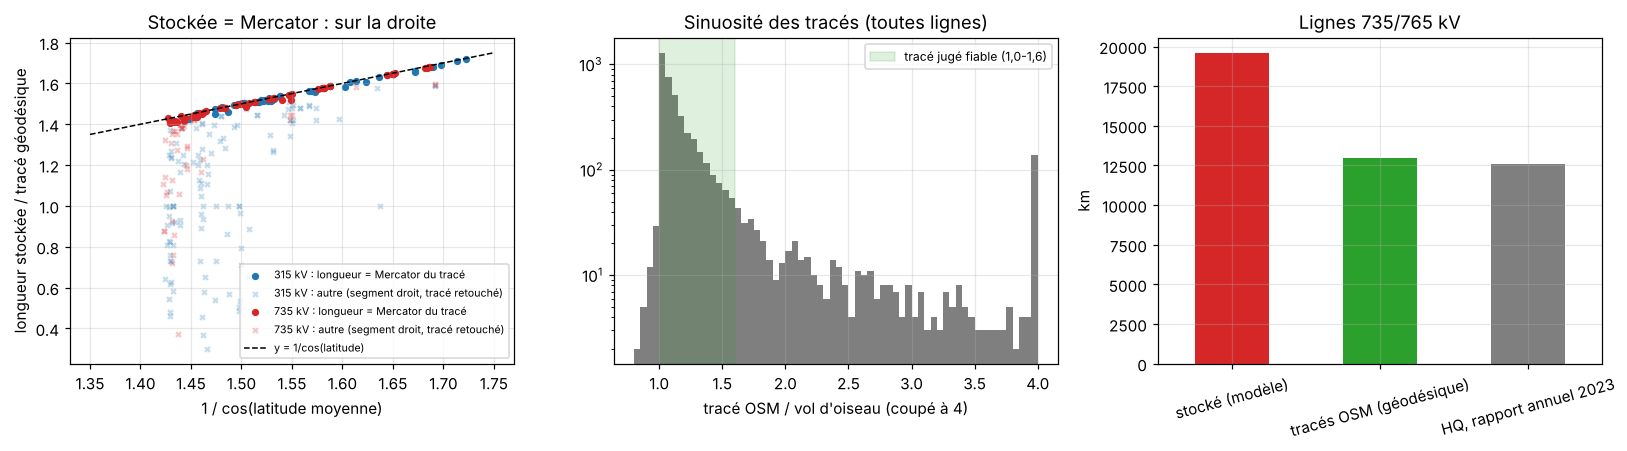

In [3]:
full = R.load(os.path.join(R.CURRENT, "elec_full.nc"))
T = R.mercator_table(full)
M = T[T.v_nom.isin([315, 735]) & (T.true_km > 5)]
M = M.assign(merc_exact=(M.stored_over_merc - 1).abs() < 0.02)
for v in [735, 315]:
    s_ = M[M.v_nom == v]
    print(f"{v} kV : {len(s_)} lignes | longueur stockée = longueur Mercator du tracé (à 2 %) : {s_.merc_exact.mean():.0%} | "
          f"stockée / géodésique : médiane {s_.stored_over_true.median():.2f} | tracé / vol d'oiseau : médiane {s_.sinuosity.median():.2f}")
km = pd.Series({"stocké (modèle)": T[T.v_nom >= 735].length_stored.sum(), "tracés OSM (géodésique)": T[T.v_nom >= 735].true_km.sum(),
                "HQ, rapport annuel 2023": 12581.0})
print("\n735/765 kV, km de lignes :"); print(km.round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for v, c in [(315, "tab:blue"), (735, "tab:red")]:
    s_ = M[(M.v_nom == v) & M.merc_exact]; o = M[(M.v_nom == v) & ~M.merc_exact]
    ax[0].scatter(s_.sec_lat, s_.stored_over_true, s=14, c=c, label=f"{v} kV : longueur = Mercator du tracé")
    ax[0].scatter(o.sec_lat, o.stored_over_true, s=10, c=c, alpha=0.25, marker="x", label=f"{v} kV : autre (segment droit, tracé retouché)")
x = np.linspace(1.35, 1.75, 10); ax[0].plot(x, x, "k--", lw=1, label="y = 1/cos(latitude)")
ax[0].set_xlabel("1 / cos(latitude moyenne)"); ax[0].set_ylabel("longueur stockée / tracé géodésique"); ax[0].legend(fontsize=7)
ax[0].set_title("Stockée = Mercator : sur la droite")
ax[1].hist(T.sinuosity.clip(upper=4), bins=np.linspace(0.8, 4, 65), color="tab:gray")
ax[1].axvspan(1.0, 1.6, color="tab:green", alpha=0.15, label="tracé jugé fiable (1,0-1,6)"); ax[1].set_yscale("log")
ax[1].set_xlabel("tracé OSM / vol d'oiseau (coupé à 4)"); ax[1].set_title("Sinuosité des tracés (toutes lignes)"); ax[1].legend(fontsize=8)
km.plot.bar(ax=ax[2], color=["tab:red", "tab:green", "tab:gray"]); ax[2].set_ylabel("km"); ax[2].set_title("Lignes 735/765 kV")
ax[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); savefig("01_longueurs_mercator.png"); plt.show()

Les points pleins tombent **exactement** sur la droite $y = 1/\cos\varphi$ : pour ces lignes (la majorité des 735 kV), la longueur stockée **est** la longueur Mercator du tracé. Les croix, sous la droite, sont des lignes dont la longueur stockée ne correspond pas à leur propre tracé : souvent la longueur Mercator d'un **segment droit** entre les deux bus (« stockée × cos φ » = vol d'oiseau), parfois un tracé OSM qui fait un détour (sinuosité 2 à 5). Dans tous les cas, la longueur stockée est fausse, et la somme des tracés du 735 kV (≈ 12 900 km, Labrador compris) retombe sur l'inventaire officiel d'HQ (12 581 km). Le 3 nov., cette surlongueur avait été repérée (« probablement la plus grosse erreur du modèle »), mais pas sa cause.

### La correction (règle hybride)
- **Tracé fiable** (extrémités à moins de 5 km des bus **et** sinuosité tracé / vol d'oiseau entre 1,0 et 1,6) : longueur = **longueur géodésique du tracé**.
- **Sinon** : longueur = **vol d'oiseau × 1,08**, la sinuosité médiane des tracés fiables.
- Puis `length`, `r`, `x`, `b` × (nouvelle / ancienne longueur), puisqu'ils sont proportionnels. On ne touche pas aux lignes modifiées depuis `elec_full` (réduction, ajouts de Nathan) ni à celles déjà justes à 2 % près.

*Note de méthode* : une première version (16 nov. au soir) multipliait simplement la longueur stockée par $\ell_\text{géodésique}/\ell_\text{Mercator}$. Elle est exacte pour les points pleins, mais elle rendait certaines lignes **plus courtes que la ligne droite** entre leurs bus (jusqu'à 0,45 ×), ce qui est impossible. La règle hybride corrige ça.

### Ce que ça change, sur un exemple : le « pont » 3360 de la Romaine
Le cours (§15) concluait que la ligne 3360 (Romaine → Arnaud, 315 kV) n'avait **aucune solution AC** : la Romaine exporte jusqu'à 696 MW, et $V^2/X$ ne valait que 673 MW. Avec sa vraie longueur (261 km au lieu de 410), $X$ passe de 147 à 94 Ω et $V^2/X$ à 1 056 MW : le problème disparaît.

In [4]:
n0 = R.load(os.path.join(R.CURRENT, "elec_solved.nc"))
rep = R.fix_lengths(n0, T)
print(rep.statut.value_counts().to_string())
ok = rep[rep.statut == "corrigée"]
print(ok.groupby(["v_nom", "methode"]).agg(lignes=("facteur", "size"), km_avant=("km_avant", "sum"), km_apres=("km_apres", "sum"),
      facteur_median=("facteur", "median")).round(2).to_string())
L0 = R.load(os.path.join(R.CURRENT, "elec_solved.nc")).lines
for l in ["3360", "161", "3535"]:
    print(f"ligne {l} ({L0.v_nom[l]:.0f} kV) : {L0.length[l]:.0f} -> {n0.lines.length[l]:.0f} km | x {L0.x[l]:.0f} -> {n0.lines.x[l]:.0f} ohm | "
          f"V²/x {L0.v_nom[l]**2/L0.x[l]:.0f} -> {n0.lines.v_nom[l]**2/n0.lines.x[l]:.0f} MW")
q0 = (L0.b * (L0.v_nom * 1e3) ** 2 / 1e9)[L0.v_nom >= 700].sum(); q1 = (n0.lines.b * (n0.lines.v_nom * 1e3) ** 2 / 1e9)[n0.lines.v_nom >= 700].sum()
print(f"capacité des lignes 735 kV à 1 pu : {q0:.1f} -> {q1:.1f} GVAr (HQ 1996 : ~30 GVAr pour 11 000 km)")

statut
corrigée                    271
sans géométrie                3
déjà à la bonne longueur      2
                                lignes  km_avant  km_apres  facteur_median
v_nom methode                                                             
315.0 tracé géodésique             108   5549.25   3824.20            0.70
      vol d'oiseau × sinuosité      57   2646.02   1436.32            0.69
345.0 tracé géodésique               1      9.70      6.76            0.70
735.0 tracé géodésique              66  14181.54   9266.75            0.67
      vol d'oiseau × sinuosité      38   5304.85   3371.11            0.68
765.0 vol d'oiseau × sinuosité       1     78.83     58.28            0.74


ligne 3360 (315 kV) : 410 -> 262 km | x 147 -> 94 ohm | V²/x 673 -> 1052 MW
ligne 161 (735 kV) : 437 -> 265 km | x 144 -> 88 ohm | V²/x 3744 -> 6168 MW
ligne 3535 (735 kV) : 471 -> 319 km | x 156 -> 105 ohm | V²/x 3473 -> 5132 MW
capacité des lignes 735 kV à 1 pu : 53.7 -> 35.5 GVAr (HQ 1996 : ~30 GVAr pour 11 000 km)


## 4. E2 — Churchill Falls : un poste coupé en deux, six circuits au lieu de trois

En regardant les lignes 735 kV corrigées, on trouve **six** lignes de 226 km entre Churchill Falls et Montagnais (bus 306), pour **trois** circuits réels (L7051-L7053) :
- les lignes **1568-1570** partent du bus **469**, le vrai poste OSM de Churchill Falls, mais ce bus n'a aucune production ;
- les lignes **L7051-L7053** ont été ajoutées par `add_churchill_falls_tie.py` depuis le bus **465-735kv**, à 1 km, où est rattachée la centrale (5 428 MW).

Dans le LOPF, les lignes L705x transitent ~1 465 MW chacune, et les lignes 1568-1570 seulement 55 MW (la charge du Labrador) : trois lignes de 226 km **presque à vide**, qui produisent ~1,8 GVAr de capacité et font monter la tension au Labrador.
**Correction** : on rattache la centrale (et sa charge locale) au poste OSM 469 et on supprime le doublon L7051-L7053.

## 5. E2b — Les chemins < 315 kV disparus : équivalents de Kron (Saguenay, Montréal)

### Le symptôme
Une fois les longueurs corrigées, deux régions décrochent à la pointe :
- **Saguenay** : une **poche de 9 bus** (3836, 2812, 1693…, ~1 GW de charge) pend à **une seule ligne 315 kV de 182 km** (la 3352, l'autre « pont » du cours). Juste à côté, le poste **Saguenay 735 kV** (bus 150) est en surtension et n'a **aucun transformateur**, alors qu'HQ le décrit comme un poste **735-161 kV** ;
- **Montréal-Ouest** : les bus 800 (3,0 GW de charge, une seule ligne) et 263 (4,4 GW) descendent à **0,89 pu**.

### La cause
Dans `elec_full.nc`, le bus 150 a bien son transformateur 735/161 kV, et un réseau 161/69/230 kV rejoint la poche (149 → 576 → 575 → 237 → 238 → 239 → **240**). La réduction au 315 kV (`reduce_voltage_network.py`) **supprime ces bus** et rattache leurs charges au bus 315 kV le plus proche, **sans rien garder des chemins qui les reliaient**. C'est systématique : **20 des 58 postes 735 kV** du modèle ont perdu leur transformation vers les tensions inférieures (Saguenay, Laval/603, Chamouchouane, La Vérendrye, Chibougamau, Grand-Brûlé, Des Cantons…). Presque partout, ça ne bloque pas. Au Saguenay et à Montréal, si.

### La correction : un équivalent de Kron régional
On prend tout le réseau < 315 kV d'`elec_full` dans une boîte (Saguenay-Lac-Saint-Jean ; île de Montréal et couronne), avec des paramètres corrigés (longueurs, **et types de lignes à 50 Hz** : $x$ et $b$ × 1,2, cf. le test β du cours). On construit sa matrice $Y$, et on **élimine** les bus qui n'existent pas dans le modèle 315 kV. Avec $b$ = bus frontières (gardés) et $e$ = bus éliminés (sans injection) :
$$
\begin{pmatrix} I_b \\ 0 \end{pmatrix} = \begin{pmatrix} Y_{bb} & Y_{be} \\ Y_{eb} & Y_{ee}\end{pmatrix}\begin{pmatrix} V_b \\ V_e\end{pmatrix}
\;\Rightarrow\; I_b = \underbrace{\left(Y_{bb} - Y_{be}\,Y_{ee}^{-1}\,Y_{eb}\right)}_{Y_\text{eq}} V_b .
$$
Chaque terme hors diagonale de $Y_\text{eq}$ donne une **branche équivalente** $z_{ij} = -1/Y_{\text{eq},ij}$ entre deux bus frontières (exactement la `ybus.py` du cours). Les charges des bus éliminés sont déjà dans le modèle : la réduction les a rattachées au 315 kV.

In [5]:
sol0 = R.load(os.path.join(R.CURRENT, "elec_solved.nc"))
for reg, box in R.KRON_REGIONS.items():
    br, sh, kinfo = R.kron_equivalent(full, sol0, T, box=box)
    tb = br.copy(); tb["x (ohm vu du 315 kV)"] = tb.z_pu.apply(lambda z: z.imag) * 315 ** 2
    tb["~V²/x (MW, 1 pu)"] = 1 / tb.z_pu.apply(lambda z: abs(z.imag))
    tb["tensions"] = [f"{sol0.buses.v_nom[a]:.0f}/{sol0.buses.v_nom[b]:.0f}" for a, b in zip(tb.bus0, tb.bus1)]
    print(f"== {reg} : {kinfo['eliminated']} bus éliminés, {kinfo['lines']} lignes < 315 kV, {len(kinfo['boundary'])} bus frontières -> {len(br)} branches équivalentes")
    print(tb.drop(columns="z_pu").sort_values("~V²/x (MW, 1 pu)", ascending=False).head(8).round(1).to_string(index=False), "\n")

== Saguenay : 41 bus éliminés, 44 lignes < 315 kV, 9 bus frontières -> 3 branches équivalentes
bus0 bus1  x (ohm vu du 315 kV)  ~V²/x (MW, 1 pu) tensions
 150  240                  33.4            2967.6  735/315
 240  286                 106.7             930.3  315/735
 150  286                 211.9             468.3  735/735 

== Montréal : 54 bus éliminés, 80 lignes < 315 kV, 30 bus frontières -> 81 branches équivalentes
bus0 bus1  x (ohm vu du 315 kV)  ~V²/x (MW, 1 pu) tensions
1715  194                  17.4            5704.9  315/315
   1  743                  19.7            5040.6  315/315
 135 1706                  23.4            4233.4  315/315
1664  676                  25.8            3839.4  315/315
1664   45                  26.0            3819.8  315/315
  45  676                  29.0            3423.3  315/315
 135 1669                  30.8            3222.9  315/315
 194  603                  32.5            3057.0  315/735 



Au Saguenay, la branche **150 → 240** (≈ 33 Ω vu du 315 kV, ~3 GW de capacité statique) *est* la transformation 735/161 kV et son réseau régional. À Montréal, on retrouve notamment la transformation du poste **603** (735/120 kV dans `elec_full`) vers le 315 kV, et des chemins 120 kV en parallèle autour des gros bus de charge. Toutes les réactances équivalentes sont positives. Une résistance très légèrement négative est bornée à zéro.

> **Limite** : on ne l'a fait que là où ça bloquait. La vraie façon de « descendre en tension » est un équivalent de Kron **provincial**, ou mieux, garder le 120-230 kV (§13).

## 6. E3-E4 — Circuits et compensation série : retrouver les corridors réels

### Identifier les postes HQ dans le modèle
Les bus n'ont pas de nom. On les identifie par leurs coordonnées **et** par la topologie connue d'HQ (dossiers de la Régie de l'énergie). Exemples : le bus **148** a exactement **sept** lignes 735 kV (« Lévis est relié au 735 kV par sept lignes », Régie R-3914-2014) ; le bus **136** relie **Duvernay (195)** et **Châteauguay (132)**, comme Chénier ; **312** est entre Némiscau (457) et La Vérendrye (308) sur le corridor ouest, comme Abitibi (IPST 2001).

In [6]:
POSTES = {"136": "Chénier", "195": "Duvernay", "677": "Bout-de-l'Île", "43": "Boucherville", "2": "Hertel", "132": "Châteauguay",
          "1081": "Grand-Brûlé", "308": "La Vérendrye", "312": "Abitibi", "310": "Chibougamau", "345": "Albanel", "457": "Némiscau",
          "340": "Radisson", "66": "LG-2", "451": "LG-3", "454": "Lemoyne", "298": "LG-4", "286": "Chamouchouane", "150": "Saguenay",
          "181": "Jacques-Cartier", "25": "Laurentides", "148": "Lévis", "114": "Manicouagan", "112": "Micoua", "85": "Arnaud",
          "306": "Montagnais", "469": "Churchill Falls", "1016": "Des Cantons", "710": "Romaine-2"}
D = R.reactive_devices_table()
D["plage par unité (Mvar)"] = D.apply(lambda r: f"{r.qmin_unit} / +{r.qmax_unit}", axis=1)
print("SVC (CLC) et compensateurs synchrones (CS) réels d'HQ, rattachés aux bus du modèle :")
print(D[["poste", "bus", "type", "nombre", "plage par unité (Mvar)", "source"]].to_string(index=False))
print(f"\nTotal : {(D.nombre * D.qmax_unit).sum():.0f} Mvar en production, {(D.nombre * D.qmin_unit).sum():.0f} Mvar en absorption")
print("\nCompensation série (E4), 40 % :")
for corr, lines in R.SERIES_CORRIDORS.items():
    print(f"  {corr} : lignes {', '.join(lines)}")

SVC (CLC) et compensateurs synchrones (CS) réels d'HQ, rattachés aux bus du modèle :
            poste bus type  nombre plage par unité (Mvar)                                                source
          Albanel 345  SVC       2            -105 / +300                          Régie R-3712-2009, tableau 2
    Chamouchouane 286  SVC       2            -300 / +300             Régie R-3712-2009 ; Hitachi Energy (±330)
      Chibougamau 310  SVC       2            -105 / +300                                     Régie R-3712-2009
      Laurentides  25  SVC       1            -100 / +350                                     Régie R-3712-2009
         Némiscau 457  SVC       2            -105 / +300                                     Régie R-3712-2009
     La Vérendrye 308  SVC       2            -105 / +300           Régie R-3712-2009 ; R-4125-2020 (-100/+300)
Lévis (déglaceur) 148  SVC       1            -125 / +250                                     Régie R-3712-2009
          Chénier 1

- **E3** : on garde la correction de Nathan (`correct_sending_end_circuits.py`, 3 circuits sur 5 corridors de départ). Elle est cohérente avec les « six lignes » qui descendent de la Baie-James (Hitachi Energy), mais n'est pas sourcée corridor par corridor : à vérifier (§12 la retire).
- **E4** : HQ a des plateformes de compensation série à **Abitibi, Chibougamau, Montagnais** (3 chacune) et **Bergeronnes** (6), qui compensent les lignes raccordées **« dans une proportion d'environ 35 % à 40 % »** (Régie, D-2016-122) ; 32 bancs à 17-40 % au total (IPST 2001). On applique donc **40 %** sur ces 8 corridors (19 lignes), au lieu des **70 %** génériques de Nathan. Ces 70 % compensaient en partie des réactances gonflées par Mercator.

## 7. E5 — Le LOPF, relancé, et une limite de stabilité qu'il ne voyait pas

On relance le LOPF de Nathan (coûts, profils, délestage à 300 000 $/MWh : tout est déjà dans `elec_solved.nc`) sur le réseau corrigé : **LOPF et AC tournent ainsi sur le même réseau**, comme demandé par la Prof. Wang. Piège PyPSA 1.3 : un `p_set` non vide fige le dispatch, on le vide avant `optimize()`.

**Capacités.** Nathan prend 3 × la courbe de **St Clair** (capacité d'une ligne en fonction de sa longueur). Avec les vraies longueurs, on a testé si ce ×3 restait nécessaire :

| marge St Clair | délestage (longueurs corrigées) |
|---|---|
| ×1 | 12,8 % |
| ×1,5 | 3,5 % |
| ×2 | 0,02 % |
| ×3 | 0 % |

Le ×3 reste nécessaire : le réseau réduit concentre les transits sur moins de lignes que le vrai. On le garde.

**Le problème.** Le LOPF ne voit pas la **stabilité** : il faisait transiter jusqu'à 945 MW sur la ligne 3360 (Romaine), pour un $V^2/X$ de 1 056 MW, soit un angle de ~60° et une consommation de réactif ($I^2X$ ≈ 770 MVAr) que les deux centrales de la poche (910 MW, ≤ 474 MVAr) ne peuvent pas fournir. Ce sont exactement les 3 heures qui sortaient de la bande.
**Correction** : $s_\text{nom} = \min\left(3\,\text{St Clair},\ \frac{V^2}{X}\sin 40°\right)$. Seule la 3360 est touchée (plafond 679 MW) ; le délestage reste **nul** pour tout plafond entre 30° et 45°.

## 8. E6 — Le réactif : ce qui manquait pour converger sans tricher

### 8.1 Un régulateur par bus, avec des limites
PyPSA attribue **tout** le réactif d'un bus PV au **premier** générateur PV du bus (vérifié). On crée donc, sur chaque bus qui a une capacité réactive, **un générateur fictif « REG bus »** (P = 0, PV) qui porte la **somme des capacités** du bus, et les vraies centrales restent en PQ à Q = 0 (elles gardent leur P du LOPF) :

| Source | $Q_\min$ | $Q_\max$ |
|---|---|---|
| Centrale synchrone (hydro, fil de l'eau, TAG), par MW installé | −0,30 | +0,48 (cos φ 0,9) |
| Éolien / solaire | −0,33 | +0,33 (cos φ 0,95) |
| SVC / CS réels (tableau §6) | plage du constructeur | plage du constructeur |

Ça remplace l'hypothèse de Nathan « Q fixe = 0,48 × p_nom même à l'arrêt » et le « réactif illimité » des bus PV. Consigne : **1,02 pu** aux régulateurs (pratique THT courante ; 1,00 pu en sensibilité, §12).

### 8.2 Inductances de ligne commutables
À chaque extrémité de ligne 735 kV (et des lignes 315 kV de plus de 100 km, ex. Fermont), une inductance égale à la **moitié de la capacité** de la ligne ($k = 1$). Le taux $k$ réellement enclenché est choisi **heure par heure et poste par poste** (§9). Repères HQ (1996) : 25 500 Mvar installés pour 30 000 Mvar de capacité ($k_\max$ ≈ 0,85), ~11 000 enclenchés à la pointe ($k$ ≈ 0,37). Ce sont des unités de 165 ou 330 Mvar manœuvrées par disjoncteurs, automatiquement (système **MAIS**, 22 postes).

### 8.3 Bancs de condensateurs aux postes de charge
Le modèle met toutes les charges à **cos φ 0,95** au 315 kV, mais ne modélise **aucun** des bancs de condensateurs de la distribution et du réseau régional (120/25 kV), qui ramènent en réalité le facteur de puissance vu du transport vers 0,98-1,0. Sans eux, il manque **~14 GVAr à la pointe**, surtout à Montréal. On ajoute à chaque poste de charge un banc commutable égal au Q de sa charge à la pointe ($\alpha = 1$ : cos φ ≈ 1 quand tout est enclenché), soit **10,8 GVAr installés**. C'est **l'hypothèse la plus forte** de ce notebook : $\alpha$ = 0,6 en sensibilité (§12), et le chiffre réel est à demander (HQ).

In [7]:
t0 = time.time()
n, info = R.build(T=T)          # E1 -> E6, avec le LOPF (10-20 s)
lopf_flows = n.lines_t.p0.copy()  # flux du LOPF, gardés pour le §10.5
for step, msg in info["log"]:
    print(f"{step:38s} {msg}")
print(f"({time.time() - t0:.0f} s)")
cap = info["ac"]["capability"]
print(f"\nCapacité réactive totale : +{cap.qmax.sum() / 1e3:.1f} / {cap.qmin.sum() / 1e3:.1f} GVAr, dont SVC/CS +{cap[cap.source.isin(['SVC', 'CS'])].qmax.sum() / 1e3:.1f} GVAr")
print(cap.groupby("source")[["qmin", "qmax"]].sum().div(1e3).round(1).rename(columns={"qmin": "Qmin (GVAr)", "qmax": "Qmax (GVAr)"}))

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


E1 longueurs                           271 lignes corrigées (175 par leur tracé, 96 par vol d'oiseau × 1.08), facteur médian 0.687
E2 Churchill Falls                     3 lignes en double supprimées, centrale rattachée au bus 469
E2b équivalent de Kron (Saguenay)      41 bus < 315 kV éliminés -> 3 branches équivalentes
E2b équivalent de Kron (Montréal)      54 bus < 315 kV éliminés -> 81 branches équivalentes
E3 circuits                            7 lignes corrigées (script de Nathan)
E4 compensation série                  40% sur 19 lignes (8 corridors)
E5 LOPF                                ok/optimal, délestage 0.000 %
E6 préparation AC                      61 régulateurs, cos phi charges 0.95, inductances de ligne 735 kV : 42026 MVAr à k = 1
E6c condensateurs                      71 postes de charge, 10835 MVAr installés (alpha = 1.0)
(11 s)

Capacité réactive totale : +28.2 / -17.8 GVAr, dont SVC/CS +6.6 GVAr
                Qmin (GVAr)  Qmax (GVAr)
source                        

## 9. E7 — Résoudre la semaine : un exploitant d'HQ, heure par heure

### 9.1 Le moteur
PyPSA met ~2,3 s par heure (dont 1,5 s pour cinq îlots HVDC d'un seul bus) : trop lent pour manœuvrer des dizaines de shunts. On a donc écrit un **Newton-Raphson polaire** (celui de `nr.py` du cours, vectorisé, avec un pas amorti) sur **la matrice $Y$ que PyPSA construit** pour le sous-réseau AC principal (199 bus) : même modèle, même convention. Vérifié contre PyPSA au départ : écart 10⁻¹⁰ pu, 34 ms au lieu de 2,3 s.

### 9.2 Les limites Q
Classique (MATPOWER) : on résout, on cherche les régulateurs hors limites, on bascule **les pires d'abord** (3 au plus par tour) en PQ à leur limite, on recommence ; un régulateur basculé revient en PV si sa tension repasse du bon côté de la consigne. Un régulateur qui a déjà changé d'état deux fois est **bloqué**, pour éviter les oscillations PV ↔ PQ. La fonction renvoie la tension **et l'état exact qui l'a produite**, et compte les régulateurs encore hors limites. *(Une première version renvoyait, après une oscillation, l'état modifié **après** le dernier calcul : à la pointe, PyPSA ne retrouvait pas la même solution. C'est la validation du §11 qui a trouvé ce bug.)*

### 9.3 La manœuvre des shunts
Premier essai : un taux $k$ **global**. Il échoue, parce qu'à la pointe Montréal manque de réactif pendant que Québec-Manicouagan en a trop. Deuxième essai : une commande **locale sur la tension**. Elle échoue aussi : l'heure de pointe diverge avant même d'avoir une tension à lire. Version retenue, **la logique d'exploitation réelle** : on manœuvre les inductances et les condensateurs **pour garder de la réserve dans les SVC, compensateurs et centrales**.

- **Phase A** (limites Q relâchées, Newton converge facilement) : chaque poste qui a des shunts lit le **réactif de son régulateur** (ou d'un voisin), sinon sa tension. Si le régulateur produit plus de 70 % de son $Q_\max$, on retire une inductance (pas de 5 %) ou on enclenche un condensateur (pas de 25 %) ; s'il absorbe plus de 70 % de son $|Q_\min|$, c'est l'inverse.
- **Phase B** : vraies limites Q (bascule PV → PQ), puis un dernier ajustement local sur la tension (inductances au-dessus de 1,04 pu, condensateurs au-dessous de 0,97 pu).

Point de départ de chaque heure : $k$ suit la charge (0,85 au creux → 0,37 à la pointe), condensateurs au prorata de la charge.

In [8]:
fs = os.path.join(OUT, "semaine_resume.csv")
eng = R.ACEngine(n, info["ac"]["regulators"])
if os.path.exists(fs):
    Tt = pd.read_csv(fs, index_col=0, parse_dates=True)
    V = pd.read_csv(os.path.join(OUT, "tensions_pu.csv"), index_col=0, parse_dates=True)
    Q = pd.read_csv(os.path.join(OUT, "regulateurs_Q_MVAr.csv"), index_col=0, parse_dates=True)
    S = pd.read_csv(os.path.join(OUT, "regulateurs_etat.csv"), index_col=0, parse_dates=True)
    K = pd.read_csv(os.path.join(OUT, "inductances_k.csv"), index_col=0, parse_dates=True)
    Cc = pd.read_csv(os.path.join(OUT, "condensateurs_c.csv"), index_col=0, parse_dates=True)
    ANG = pd.read_csv(os.path.join(OUT, "angles_deg.csv"), index_col=0, parse_dates=True)
    print("Résultats chargés depuis resultats/ (produits par construire.py).")
else:
    t0 = time.time()
    Tt, Vc, Q, K, Cc, S = R.solve_week_reserve(eng)
    V = Vc.abs(); ANG = pd.DataFrame(np.degrees(np.angle(Vc.values.astype(complex))), index=Vc.index, columns=Vc.columns)
    print(f"Semaine résolue en {time.time() - t0:.0f} s.")
for c in ["converged", "in_hard", "in_band"]:
    Tt[c] = Tt[c].astype(str).str.lower().eq("true") if Tt[c].dtype == object else Tt[c].fillna(False).astype(bool)
load = n.loads_t.p_set.sum(axis=1)
print(f"Heures convergées : {int(Tt.converged.sum())}/168")
print(f"Toutes les tensions dans 0,90-1,10 pu : {int(Tt.in_hard.sum())}/168 | dans 0,95-1,05 pu : {int(Tt.in_band.sum())}/168")
print(f"Tensions sur la semaine : {Tt.v_min.min():.3f} - {Tt.v_max.max():.3f} pu (735 kV : {Tt.v735_min.min():.3f} - {Tt.v735_max.max():.3f})")
print(f"Régulateurs en butée (basculés en PQ) : {Tt.n_pq.mean():.1f} en moyenne, {int(Tt.n_pq.max())} au plus, sur {len(eng.regs)}")
if "regulateurs_hors_limites" in Tt:
    print(f"Heures où un régulateur resté en PV dépasse ses limites Q : {int((Tt.regulateurs_hors_limites > 0).sum())}/168")
# complémentarité : un régulateur en butée haute doit avoir V <= consigne (sinon il réduirait son Q), et l'inverse en butée basse
rb = {g: eng.buses[b] for g, b in zip(eng.regs, eng.reg_bus)}; vset = pd.Series(eng.vset, index=eng.buses)
cmp = [(sn, g, V.at[sn, rb[g]] - vset[rb[g]]) for sn in S.index for g in S.columns
       if (S.at[sn, g] > 0 and V.at[sn, rb[g]] > vset[rb[g]] + 1e-3) or (S.at[sn, g] < 0 and V.at[sn, rb[g]] < vset[rb[g]] - 1e-3)]
print(f"Régulateurs en butée du « mauvais » côté de leur consigne (> 0,001 pu) : {len(cmp)} cas sur la semaine"
      + "".join(f"\n   {sn} : {g} à sa limite, tension {d:+.4f} pu au-dessus de la consigne" for sn, g, d in cmp))
bad = Tt.index[~Tt.in_band]
for s in bad:
    print(f"  hors 0,95-1,05 : {s} — V min {V.loc[s].min():.3f} au bus {V.loc[s].idxmin()}")

Résultats chargés depuis resultats/ (produits par construire.py).
Heures convergées : 168/168
Toutes les tensions dans 0,90-1,10 pu : 168/168 | dans 0,95-1,05 pu : 165/168
Tensions sur la semaine : 0.922 - 1.035 pu (735 kV : 0.978 - 1.035)
Régulateurs en butée (basculés en PQ) : 12.1 en moyenne, 21 au plus, sur 61
Heures où un régulateur resté en PV dépasse ses limites Q : 0/168
Régulateurs en butée du « mauvais » côté de leur consigne (> 0,001 pu) : 1 cas sur la semaine
   2022-01-03 17:00:00 : REG 131 à sa limite, tension +0.0094 pu au-dessus de la consigne
  hors 0,95-1,05 : 2022-01-03 17:00:00 — V min 0.922 au bus 800
  hors 0,95-1,05 : 2022-01-03 18:00:00 — V min 0.933 au bus 800
  hors 0,95-1,05 : 2022-01-04 10:00:00 — V min 0.944 au bus 800


**Les 3 heures sous 0,95 pu** sont les trois plus chargées (pointe du 3 janv. 17 h-18 h, 4 janv. 10 h) : à Montréal-Ouest (bus 800 et 263, 3 et 4,4 GW de charge agrégée), toutes les sources de réactif de la région sont **en butée haute** (Chénier, Duvernay, Lévis, Laurentides, La Vérendrye, Manicouagan). La tension descend alors à 0,92-0,94 pu. Ce n'est pas un échec numérique, c'est un **constat** : à 35 GW, le cas de base n'a plus de réserve réactive à Montréal (cf. la marge de charge, §11.2).

**Un point imparfait, à la pointe seulement.** Le régulateur de Beauharnois (bus 131) est en butée à $Q_\max$ avec une tension 0,009 pu **au-dessus** de sa consigne : en toute rigueur, il devrait revenir en PV et baisser un peu son Q. Mais remis en PV, il demande ~1 200 MVAr pour 975 de capacité (et trois autres régulateurs sortent alors de leurs limites) : la boucle PV ↔ PQ n'a pas de point parfaitement cohérent à cette heure, signe qu'on est au bord de la marge (§11.2). MATPOWER et pandapower acceptent ce type de solution (ils ne revérifient jamais le passage PQ → PV) ; c'est le seul cas de la semaine.

*Reproductibilité.* Le LOPF a **plusieurs solutions de même coût** (beaucoup de centrales hydro au même coût marginal). Selon celle que HiGHS retient, le dispatch change un peu, et la tension minimale aussi (0,92 à 0,96 pu selon les essais). Le code fixe maintenant l'ordre des composants : deux exécutions donnent exactement le même dispatch, au MW près. Pour la suite, ce serait mieux de **lever cette dégénérescence** (petits écarts de coût entre centrales, ou pertes dans le LOPF).

## 10. Résultats

### 10.1 Les tensions sur la semaine

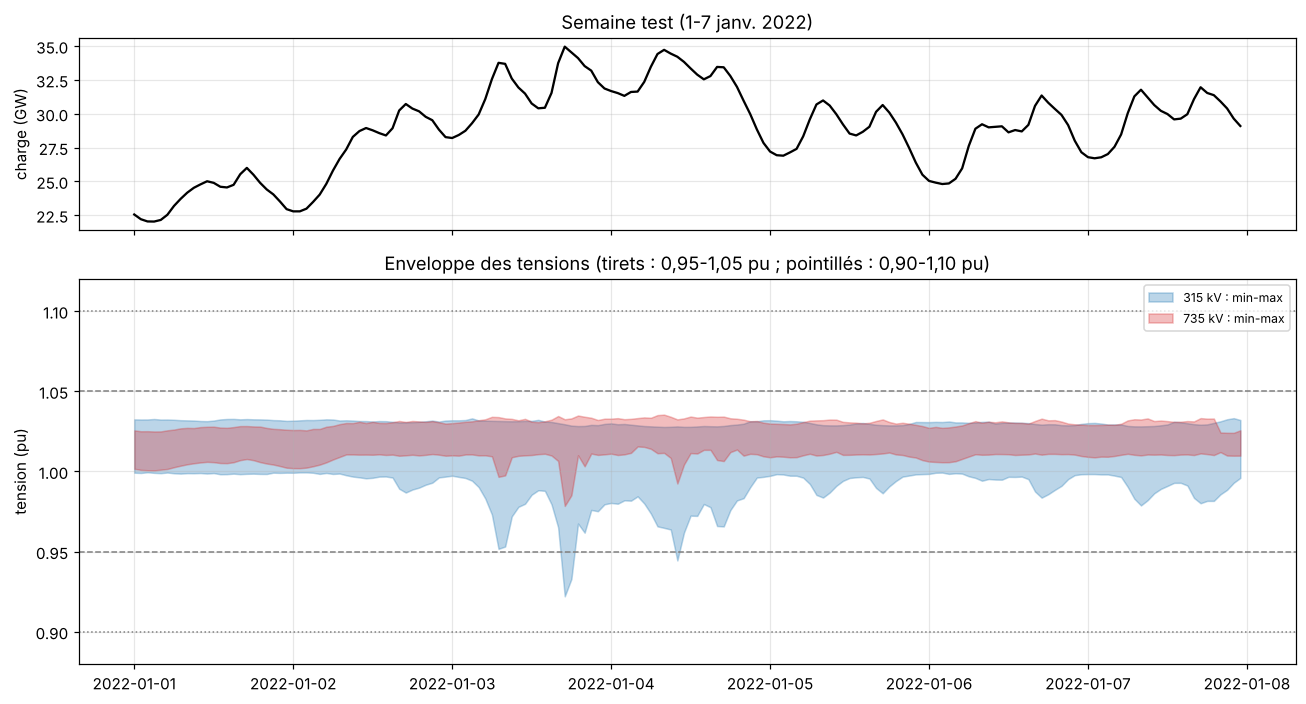

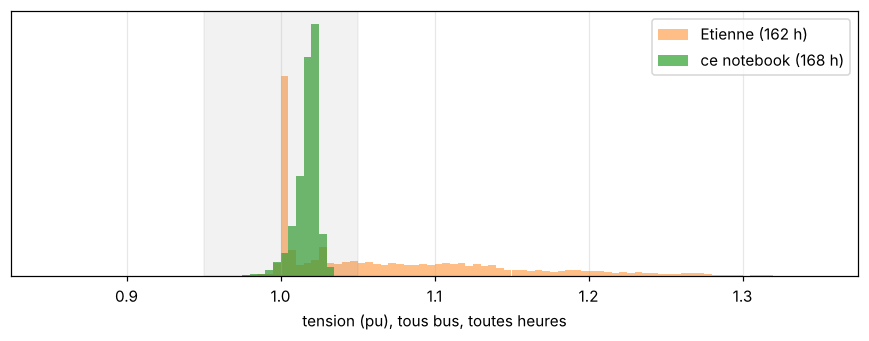

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
ax[0].plot(load.index, load / 1e3, c="k"); ax[0].set_ylabel("charge (GW)"); ax[0].set_title("Semaine test (1-7 janv. 2022)")
b735 = [b for b in V.columns if n.buses.v_nom[b] >= 700]; b315 = [b for b in V.columns if n.buses.v_nom[b] < 700]
for cols, c, lab in [(b315, "tab:blue", "315 kV"), (b735, "tab:red", "735 kV")]:
    ax[1].fill_between(V.index, V[cols].min(axis=1), V[cols].max(axis=1), color=c, alpha=0.3, label=f"{lab} : min-max")
for y, ls in [(0.95, "--"), (1.05, "--"), (0.90, ":"), (1.10, ":")]:
    ax[1].axhline(y, c="gray", ls=ls, lw=1)
ax[1].set_ylabel("tension (pu)"); ax[1].legend(loc="upper right", fontsize=8); ax[1].set_ylim(0.88, 1.12)
ax[1].set_title("Enveloppe des tensions (tirets : 0,95-1,05 pu ; pointillés : 0,90-1,10 pu)")
plt.tight_layout(); savefig("02_tensions_semaine.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0.85, 1.35, 101)
if V_etienne is not None:
    ax.hist(V_etienne.values.ravel(), bins=bins, alpha=0.5, color="tab:orange", label="Etienne (162 h)", density=True)
ax.hist(V.values.ravel(), bins=bins, alpha=0.7, color="tab:green", label="ce notebook (168 h)", density=True)
ax.axvspan(0.95, 1.05, color="gray", alpha=0.1); ax.set_xlabel("tension (pu), tous bus, toutes heures"); ax.legend(); ax.set_yticks([])
plt.tight_layout(); savefig("03_histogramme_tensions.png"); plt.show()

### 10.2 La carte, à la pointe et au creux

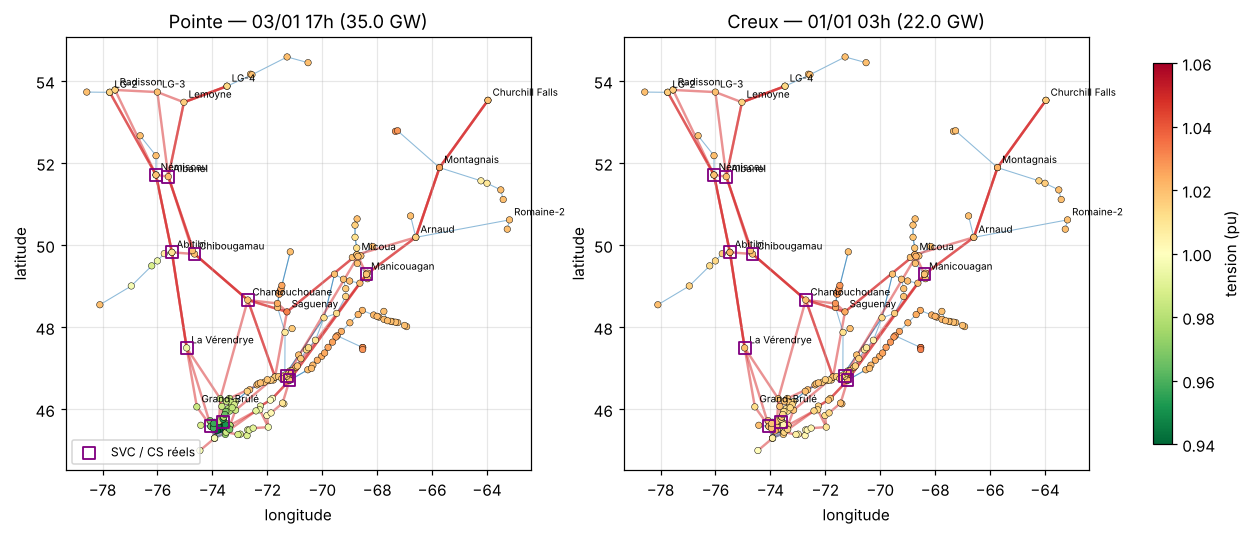

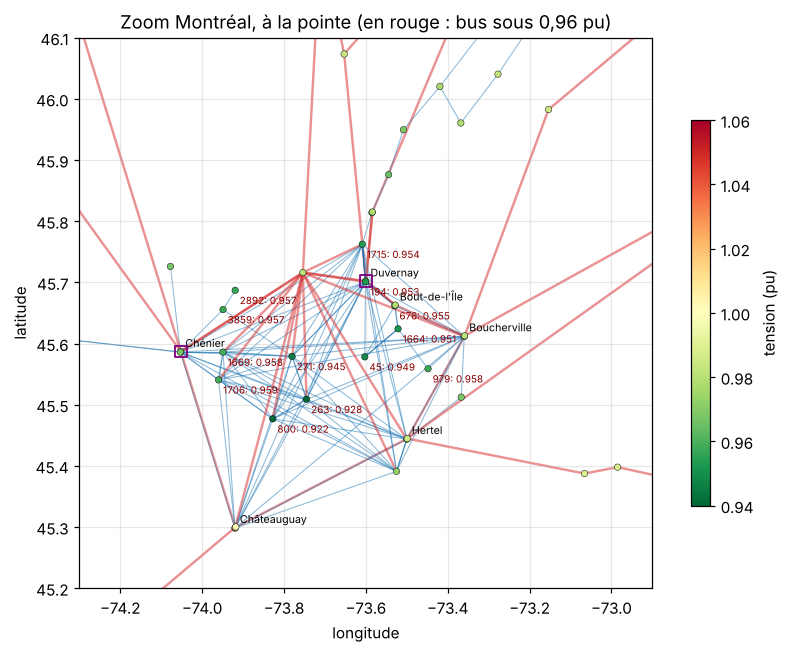

In [10]:
def carte(ax, sn, title, box=None, crowded=("Bout-de-l'Île", "Boucherville", "Hertel", "Duvernay", "Chénier", "Châteauguay",
                                                "Des Cantons", "Laurentides", "Jacques-Cartier", "Lévis")):
    vm = V.loc[sn]
    for df in (n.lines, n.transformers):
        for _, r in df.iterrows():
            if r.bus0 in n.buses.index and r.bus1 in n.buses.index:
                v = n.buses.v_nom[r.bus0]
                ax.plot([n.buses.x[r.bus0], n.buses.x[r.bus1]], [n.buses.y[r.bus0], n.buses.y[r.bus1]],
                        c="tab:red" if v >= 700 else "tab:blue", lw=1.6 if v >= 700 else 0.7, alpha=0.5, zorder=1)
    b = vm.index
    sc = ax.scatter(n.buses.x[b], n.buses.y[b], c=vm.values, cmap="RdYlGn_r", vmin=0.94, vmax=1.06, s=18, zorder=3, edgecolors="k", linewidths=0.3)
    dev = R.reactive_devices_table().bus.unique()
    ax.scatter(n.buses.x[dev], n.buses.y[dev], marker="s", s=60, facecolors="none", edgecolors="purple", lw=1.2, zorder=4, label="SVC / CS réels")
    for bus, name in POSTES.items():
        if bus in n.buses.index and (box is not None or name not in crowded):
            if box is None or (box[0] <= n.buses.x[bus] <= box[1] and box[2] <= n.buses.y[bus] <= box[3]):
                ax.annotate(name, (n.buses.x[bus], n.buses.y[bus]), fontsize=7 if box else 6.5, xytext=(3, 3), textcoords="offset points")
    if box is not None:
        for b in vm.index:
            if box[0] <= n.buses.x[b] <= box[1] and box[2] <= n.buses.y[b] <= box[3] and vm[b] < 0.96:
                ax.annotate(f"{b}: {vm[b]:.3f}", (n.buses.x[b], n.buses.y[b]), fontsize=6.5, color="darkred", xytext=(3, -9), textcoords="offset points")
        ax.set_xlim(box[0], box[1]); ax.set_ylim(box[2], box[3])
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect(1 / np.cos(np.radians(48)))
    return sc
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
sc = carte(ax[0], PEAK, f"Pointe — {PEAK:%d/%m %Hh} ({load[PEAK]/1e3:.1f} GW)")
carte(ax[1], NIGHT, f"Creux — {NIGHT:%d/%m %Hh} ({load[NIGHT]/1e3:.1f} GW)")
ax[0].legend(loc="lower left", fontsize=8)
fig.colorbar(sc, ax=ax, shrink=0.6, label="tension (pu)")
savefig("04_carte_pointe_creux.png"); plt.show()
fig, ax = plt.subplots(figsize=(9, 6.5))
sc = carte(ax, PEAK, "Zoom Montréal, à la pointe (en rouge : bus sous 0,96 pu)", box=(-74.3, -72.9, 45.2, 46.1))
fig.colorbar(sc, ax=ax, shrink=0.7, label="tension (pu)"); savefig("04b_zoom_montreal_pointe.png"); plt.show()

### 10.3 Les shunts : un comportement d'exploitant… proche de celui d'HQ
Ni le taux d'inductances ni celui des condensateurs ne sont imposés : la commande les choisit heure par heure pour garder de la réserve dans les régulateurs. On les compare ensuite aux chiffres d'HQ.

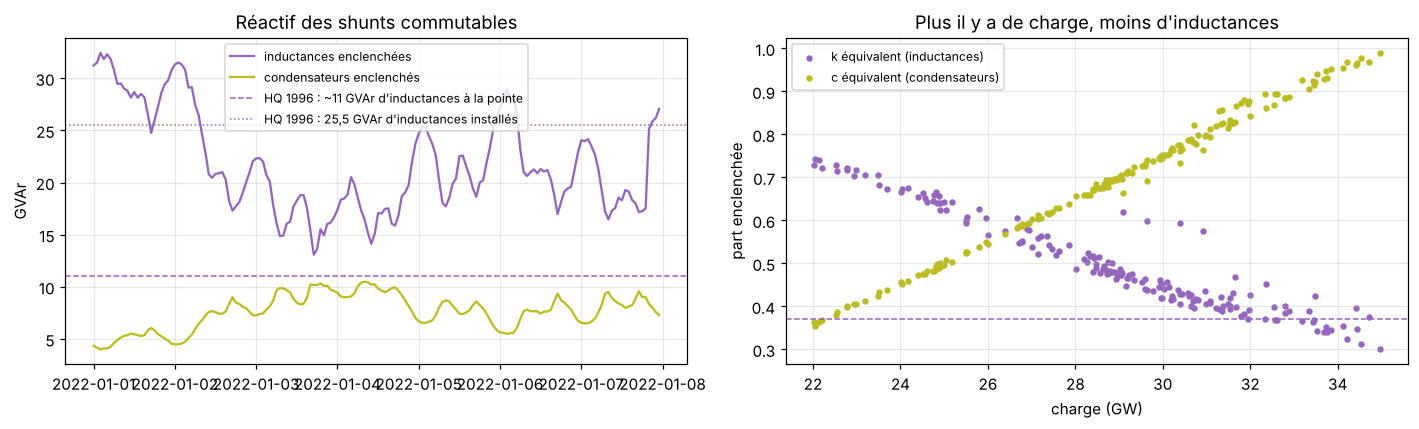

À la pointe : 13.1 GVAr d'inductances (k = 0.30) ; HQ : ~11 GVAr (k ≈ 0,37)
Au creux    : 31.8 GVAr (k = 0.73) ; HQ : 25,5 GVAr installés au total


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(Tt.index, Tt.q_react_MVAr / 1e3, label="inductances enclenchées", c="tab:purple")
ax[0].plot(Tt.index, Tt.q_cap_MVAr / 1e3, label="condensateurs enclenchés", c="tab:olive")
ax[0].axhline(11, c="tab:purple", ls="--", lw=1, label="HQ 1996 : ~11 GVAr d'inductances à la pointe")
ax[0].axhline(25.5, c="tab:purple", ls=":", lw=1, label="HQ 1996 : 25,5 GVAr d'inductances installés")
ax[0].set_ylabel("GVAr"); ax[0].legend(fontsize=8); ax[0].set_title("Réactif des shunts commutables")
ax[1].scatter(load / 1e3, Tt.k_eq, s=10, label="k équivalent (inductances)", c="tab:purple")
ax[1].scatter(load / 1e3, Tt.c_eq, s=10, label="c équivalent (condensateurs)", c="tab:olive")
ax[1].axhline(0.37, c="tab:purple", ls="--", lw=1); ax[1].set_xlabel("charge (GW)"); ax[1].set_ylabel("part enclenchée")
ax[1].legend(fontsize=8); ax[1].set_title("Plus il y a de charge, moins d'inductances")
plt.tight_layout(); savefig("05_shunts.png"); plt.show()
print(f"À la pointe : {Tt.q_react_MVAr[PEAK] / 1e3:.1f} GVAr d'inductances (k = {Tt.k_eq[PEAK]:.2f}) ; HQ : ~11 GVAr (k ≈ 0,37)")
print(f"Au creux    : {Tt.q_react_MVAr[NIGHT] / 1e3:.1f} GVAr (k = {Tt.k_eq[NIGHT]:.2f}) ; HQ : 25,5 GVAr installés au total")

À la pointe, le modèle enclenche **~13 GVAr** d'inductances (k ≈ 0,30) quand HQ en a **~11** (k ≈ 0,37) ; la nuit, **~32 GVAr** (k ≈ 0,73) pour 25,5 installés chez HQ. Le **taux** $k$ est presque celui d'HQ : avec des longueurs justes, les besoins en compensation du modèle ressemblent à ceux du vrai réseau. (Le total est un peu plus haut parce que le modèle a ~20 % de km de 735 kV en plus que HQ en 1996, Labrador compris.)

### 10.4 Les régulateurs : qui est en butée, et quand

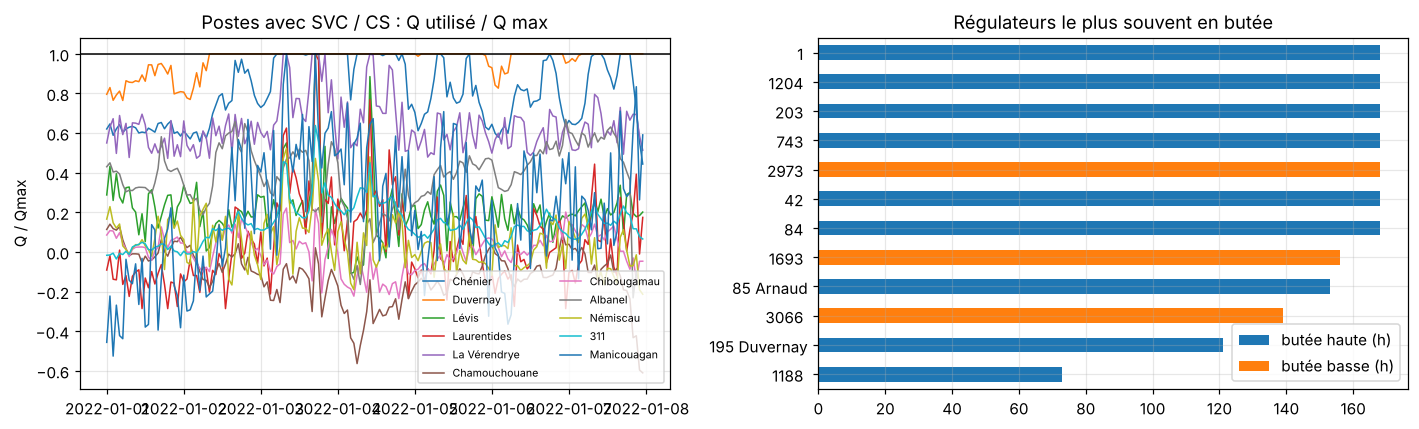

Slack (339 slack-placeholder, LG-2, 7722 MW) : Q entre -127 et 901 MVAr, capacité [-2317, 3707] -> dans ses limites


In [12]:
names = {r: (POSTES.get(r[4:], r[4:])) for r in eng.regs}
sites = [f"REG {b}" for b in ["136", "195", "148", "25", "308", "286", "310", "345", "457", "311", "114"] if f"REG {b}" in Q.columns]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for g in sites:
    j = eng.regs.index(g)
    ax[0].plot(Q.index, Q[g] / max(eng.qmax[j], 1), lw=1, label=names[g])
ax[0].axhline(1, c="k", lw=1); ax[0].set_ylabel("Q / Qmax"); ax[0].set_title("Postes avec SVC / CS : Q utilisé / Q max")
ax[0].legend(fontsize=7, ncol=2)
sat_hi = (S == 1).sum(); sat_lo = (S == -1).sum()
top = (sat_hi + sat_lo).sort_values(ascending=False).head(12)
pd.DataFrame({"butée haute (h)": sat_hi[top.index], "butée basse (h)": sat_lo[top.index]}).rename(index=lambda r: f"{r[4:]} {names[r] if names[r] != r[4:] else ''}").plot.barh(ax=ax[1], stacked=True)
ax[1].set_title("Régulateurs le plus souvent en butée"); ax[1].invert_yaxis()
plt.tight_layout(); savefig("06_regulateurs.png"); plt.show()
sl = n.generators.index[n.generators.control == "Slack"]; big = n.generators.loc[sl].p_nom.idxmax()
print(f"Slack ({big}, LG-2, {n.generators.p_nom[big]:.0f} MW) : Q entre {Tt.q_slack.min():.0f} et {Tt.q_slack.max():.0f} MVAr, capacité [{n.generators.q_min[big]:.0f}, {n.generators.q_max[big]:.0f}] -> dans ses limites")

Les régulateurs en butée **haute** sont surtout de petites centrales et des parcs éoliens raccordés directement à de gros postes (ex. bus 42, Boucherville 315 kV, où la seule source est une ferme solaire de 2 MW : elle passe en PQ et c'est normal). Les butées **basses** sont la nuit au nord (Manicouagan, Lévis, LG) : les lignes longues peu chargées fournissent du réactif que les inductances (bornées à $k$ = 0,85) ne compensent pas entièrement.

### 10.5 Transits : DC (LOPF) contre AC, et les angles

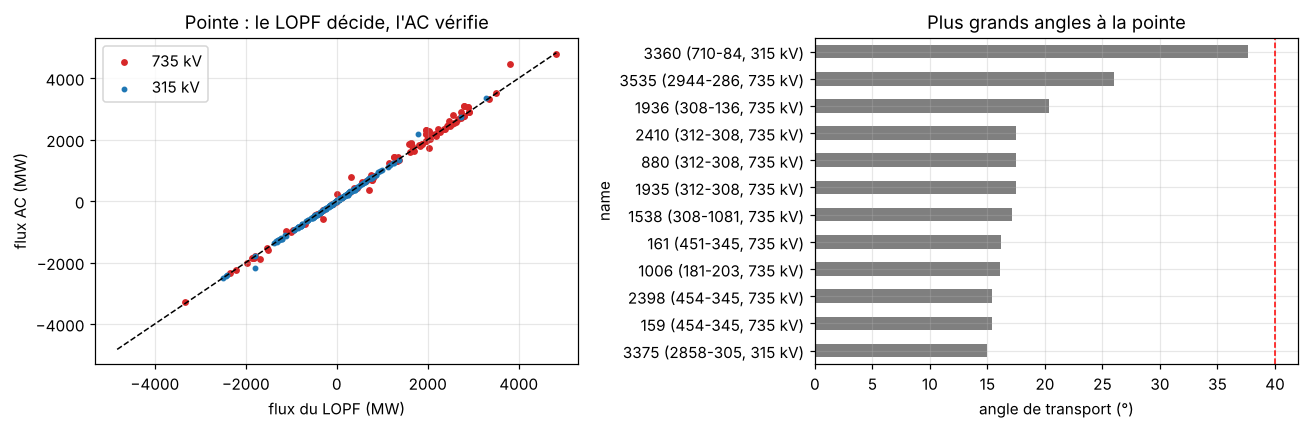

PyPSA converge à la pointe : True
Pertes AC à la pointe : 1801 MW (5.2 % de la charge) ; le LOPF est sans pertes, c'est le slack (LG-2) qui les fournit
Écart LOPF/AC sur les lignes 735 kV : médiane 32 MW, max 662 MW (ligne 162)


In [13]:
# état final de la pointe recopié dans PyPSA, puis AC PF de PyPSA : flux AC ; flux du LOPF gardés au §8
R.apply_hour_state(n, eng, PEAK, K.reindex(columns=eng.buses).fillna(0), Cc.reindex(columns=eng.buses).fillna(0), S)
with R.quiet():
    n.lpf([PEAK]); res = n.pf([PEAK], use_seed=True)
flows_ac = n.lines_t.p0.loc[PEAK]; flows_lopf = lopf_flows.loc[PEAK]
m = n.lines.v_nom >= 700
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(flows_lopf[m], flows_ac[m], s=12, c="tab:red", label="735 kV"); ax[0].scatter(flows_lopf[~m], flows_ac[~m], s=8, c="tab:blue", label="315 kV")
lim = max(flows_lopf.abs().max(), flows_ac.abs().max()); ax[0].plot([-lim, lim], [-lim, lim], "k--", lw=1)
ax[0].set_xlabel("flux du LOPF (MW)"); ax[0].set_ylabel("flux AC (MW)"); ax[0].set_title("Pointe : le LOPF décide, l'AC vérifie"); ax[0].legend()
d = (n.buses_t.v_ang.loc[PEAK, n.lines.bus0].values - n.buses_t.v_ang.loc[PEAK, n.lines.bus1].values)
ang = pd.Series(np.degrees(np.abs(d)), index=n.lines.index).sort_values(ascending=False)
ang.head(12).rename(index=lambda l: f"{l} ({n.lines.bus0[l]}-{n.lines.bus1[l]}, {n.lines.v_nom[l]:.0f} kV)").plot.barh(ax=ax[1], color="tab:gray")
ax[1].axvline(40, c="r", ls="--", lw=1); ax[1].invert_yaxis(); ax[1].set_xlabel("angle de transport (°)"); ax[1].set_title("Plus grands angles à la pointe")
plt.tight_layout(); savefig("07_lopf_ac_angles.png"); plt.show()
loss = (n.lines_t.p0.loc[PEAK] + n.lines_t.p1.loc[PEAK]).sum() + (n.transformers_t.p0.loc[PEAK] + n.transformers_t.p1.loc[PEAK]).sum()
print(f"PyPSA converge à la pointe : {bool(res.converged.all(axis=1).iloc[0])}")
print(f"Pertes AC à la pointe : {loss:.0f} MW ({100 * loss / load[PEAK]:.1f} % de la charge) ; le LOPF est sans pertes, c'est le slack (LG-2) qui les fournit")
e = (flows_ac[m] - flows_lopf[m]).abs()
print(f"Écart LOPF/AC sur les lignes 735 kV : médiane {e.median():.0f} MW, max {e.max():.0f} MW (ligne {e.idxmax()})")

## 11. Validation

### 11.1 Trois solveurs, la même réponse
Pour chaque heure, on recopie l'état final (inductances et condensateurs enclenchés, régulateurs en PV ou en PQ à leur limite) dans le réseau PyPSA et on relance **le solveur de PyPSA à froid** (départ DC, sans la solution du moteur). Puis on exporte l'heure au format **MATPOWER** et on la résout avec **pandapower**, d'abord dans le même état, puis en laissant **pandapower appliquer lui-même les limites Q**.

In [14]:
fp, fpp = os.path.join(OUT, "validation_pypsa.csv"), os.path.join(OUT, "validation_pandapower.csv")
if os.path.exists(fp):
    Dp = pd.read_csv(fp, index_col=0, parse_dates=True)
    print(f"PyPSA (départ à froid) : {int(Dp.pypsa_converge.sum())}/{len(Dp)} heures convergées | écart |V| max {Dp.ecart_V_max.max():.1e} pu | écart d'angle max {Dp.ecart_angle_deg_max.max():.1e}°")
    print(f"   même solution que le moteur (écart < 1e-4 pu) : {int((Dp.ecart_V_max < 1e-4).sum())}/{len(Dp)} heures")
else:
    print("validation_pypsa.csv absent : lancer construire.py --valider")
if os.path.exists(fpp):
    Dpp = pd.read_csv(fpp, index_col=0, parse_dates=True)
    print(f"pandapower, même état  : {int(Dpp.converge.sum())}/{len(Dpp)} | écart |V| max {Dpp.ecart_V_max.max():.1e} pu | bus PV hors limites : {int(Dpp.bus_PV_hors_limites.max())}")
    print(f"pandapower, ses propres limites Q (départ à chaud) : {int(Dpp.limites_Q_pandapower_ok.sum())}/{len(Dpp)} heures convergées")
else:
    print("validation_pandapower.csv absent (pandapower non installé ?)")

PyPSA (départ à froid) : 168/168 heures convergées | écart |V| max 1.9e-07 pu | écart d'angle max 3.9e-06°
   même solution que le moteur (écart < 1e-4 pu) : 168/168 heures
pandapower, même état  : 168/168 | écart |V| max 1.9e-07 pu | bus PV hors limites : 0
pandapower, ses propres limites Q (départ à chaud) : 168/168 heures convergées


### 11.2 La marge de charge à la pointe (courbe P-V)
On multiplie charge **et** production de l'heure de pointe par $\lambda$, par pas de 0,5 %, jusqu'au premier pas **sans solution qui respecte les limites Q** (`R.load_margin`). (a) shunts figés dans leur état de la pointe ; (b) shunts re-manœuvrés à chaque pas, comme le ferait l'exploitant.

*Attention au critère.* Au-delà de la limite, Newton peut encore « converger », mais seulement en laissant des régulateurs en PV **au-dessus de leur Qmax**, ou des régulateurs en butée avec une tension **au-dessus de leur consigne** (non physique : ils baisseraient leur Q). Un pas n'est donc compté que si les deux sont respectés (à 0,01 pu près pour le second). Sans ces critères, on lirait ×1,08 (première version), puis ×1,015 : c'était faux les deux fois.

In [15]:
sn = PEAK
k0 = K.reindex(columns=eng.buses).fillna(0).loc[sn].values; c0 = Cc.reindex(columns=eng.buses).fillna(0).loc[sn].values
curves = {"shunts figés": R.load_margin(eng, sn, k0, c0, mode="fige"),
          "shunts re-manœuvrés": R.load_margin(eng, sn, mode="remanoeuvre")}
for mode, d in curves.items():
    print(f"{mode} : λ max ≈ {d.lam.max():.3f} ({load[sn] * d.lam.max() / 1e3:.1f} GW) ; au dernier pas : V min {d.v_min.iloc[-1]:.3f} au bus {d.bus_v_min.iloc[-1]}, {d.n_pq.iloc[-1]} régulateurs en butée")
fs = os.path.join(OUT, "sensibilites.csv")
if os.path.exists(fs):
    MV = pd.read_csv(fs)[["variante", "marge_pointe_lambda"]].dropna()
    MV["charge max (GW)"] = (MV.marge_pointe_lambda * load[sn] / 1e3).round(1)
    print("\nMarge (shunts re-manœuvrés) des variantes du §12 (sensibilites.py) :")
    with pd.option_context("display.width", 200, "display.max_colwidth", 70):
        print(MV.rename(columns={"marge_pointe_lambda": "λ max"}).to_string(index=False))

shunts figés : λ max ≈ 1.000 (35.0 GW) ; au dernier pas : V min 0.922 au bus 800, 21 régulateurs en butée
shunts re-manœuvrés : λ max ≈ 1.000 (35.0 GW) ; au dernier pas : V min 0.922 au bus 800, 21 régulateurs en butée

Marge (shunts re-manœuvrés) des variantes du §12 (sensibilites.py) :
                                                     variante  λ max  charge max (GW)
                                                    Cas final  1.000             35.0
                      Sans correction de Churchill Falls (E2)  1.050             36.7
                               Sans équivalents de Kron (E2b)  1.005             35.1
               Équivalent de Kron au Saguenay seulement (E2b)  1.010             35.3
                  Sans correction des circuits de Nathan (E3)  1.015             35.5
Compensation série 70 % sur les 19 lignes Nathan/Etienne (E4)  1.060             37.1
                                 Sans compensation série (E4)  1.000             35.0
                  Sans 

**Le cas de base est au nez de la courbe P-V à la pointe.** Dès **+0,5 %** de charge, il n'existe plus de solution qui respecte les limites Q, qu'on re-manœuvre les shunts ou non. Le vrai réseau a tenu **43,1 GW** en février 2023 (×1,23 la pointe de cette semaine) : le modèle sous-estime nettement la marge. pandapower confirme : dans l'état figé de la pointe, il ne converge plus à +1 % de charge, même sans limites Q.

**Ce qui coince** (diagnostic à $\lambda$ = 1,02) : toutes les sources de réactif du **sud** (latitude 45-47° : Montréal, Québec, Mauricie) sont en butée haute, alors que les angles s'étalent sur **~120°** entre LG-2 et Montréal (38° sur la seule ligne 3360). Le transit nord-sud consomme du réactif dans les lignes ($I^2X$, §2) et le sud n'a plus de quoi tenir sa tension : c'est exactement le problème qu'HQ a réglé avec la compensation série et les SVC.

**Les leviers** (tableau ci-dessus ; chaque variante a son propre LOPF, donc des écarts de ±1 % entre variantes proches ne veulent rien dire) : bancs de condensateurs ×1,5 → marge ×1,115 (39 GW) ; compensation série 70 % → ×1,06 ; un autre dispatch du LOPF (sans plafond de stabilité) → ×1,055 ; consigne 1,04 pu → ×1,015 ; le cos φ des charges presque rien. La marge dépend donc surtout du **réactif installé dans le sud**, c'est-à-dire des deux données les moins sourcées (Mvar de condensateurs par poste, liste des bancs série). **Je n'ai pas changé α pour « caler » la marge** : sans données HQ, ce serait ajuster le modèle au résultat voulu.

**Pour AC-CFM**, c'est le point à dire : à la pointe, presque n'importe quel déclenchement fera s'effondrer la tension *dans le modèle*. Avant les cascades, il faut soit obtenir le réactif réel du sud, soit étudier une heure moins chargée, soit présenter la marge comme une limite connue.

## 12. Alternatives de conception : une hypothèse retirée à la fois

Le cours demande des **alternatives comparées** et des **décisions justifiées**. Chaque ligne ci-dessous refait toute la semaine (LOPF + 168 h d'AC avec limites Q) en retirant ou changeant **une seule** hypothèse du cas final (`sensibilites.py`), puis calcule la marge de charge à la pointe (§11.2).

Colonnes : **Newton** = heures où Newton converge ; **conv. (lim. Q)** = heures où, en plus, tous les régulateurs sont dans leurs limites Q (notre définition de « convergé ») ; puis les heures dans chaque bande de tension (parmi les convergées) ; **marge λ** = facteur de charge maximal à la pointe.

                                                     variante  délest. %  Newton  conv. (lim. Q)  0,90-1,10  0,95-1,05  v_min  v_max  induct. pointe GVAr  marge λ
                                                    Cas final        0.0     168             168        168        165  0.922  1.035                 13.1    1.000
                           Sans correction des longueurs (E1)        0.0     168             159        158        130  0.937  1.118                  NaN      NaN
                      Sans correction de Churchill Falls (E2)        0.0     168             168        168        168  0.952  1.040                 16.6    1.050
                               Sans équivalents de Kron (E2b)        0.0     168             168        165        155  0.885  1.034                 14.6    1.005
               Équivalent de Kron au Saguenay seulement (E2b)        0.0     168             167        164        155  0.887  1.034                 15.0    1.010
                  Sans

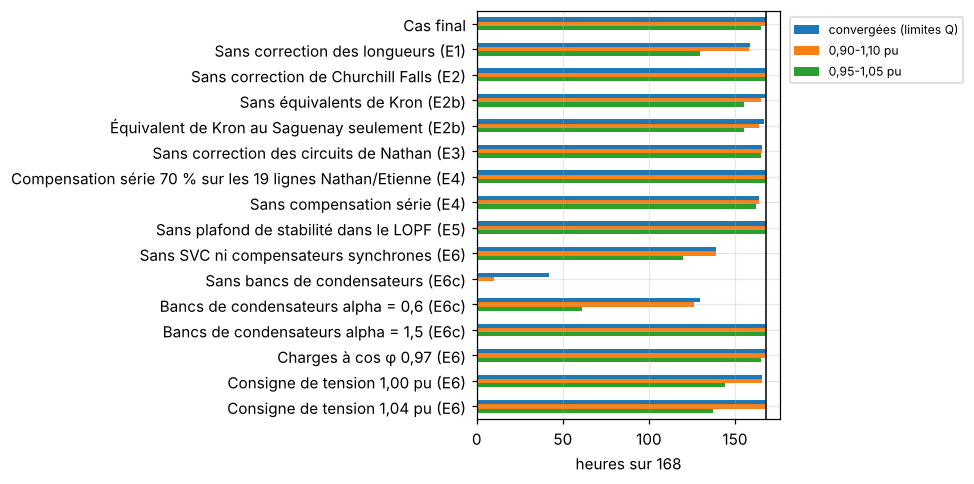

In [16]:
fsen = os.path.join(OUT, "sensibilites.csv")
if os.path.exists(fsen):
    SEN = pd.read_csv(fsen)
    cols = [c for c in ["variante", "lopf_delestage_pct", "newton", "convergees", "bande_090_110", "bande_095_105", "v_min", "v_max", "inductances_pointe_GVAr", "marge_pointe_lambda"] if c in SEN]
    with pd.option_context("display.width", 250, "display.max_colwidth", 70):
        print(SEN[cols].rename(columns={"lopf_delestage_pct": "délest. %", "newton": "Newton", "convergees": "conv. (lim. Q)", "bande_090_110": "0,90-1,10", "bande_095_105": "0,95-1,05",
                                        "inductances_pointe_GVAr": "induct. pointe GVAr", "marge_pointe_lambda": "marge λ"}).to_string(index=False))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    s = SEN.set_index("variante")
    s[["convergees", "bande_090_110", "bande_095_105"]].rename(columns={"convergees": "convergées (limites Q)", "bande_090_110": "0,90-1,10 pu", "bande_095_105": "0,95-1,05 pu"}).plot.barh(ax=ax)
    ax.axvline(168, c="k", lw=1); ax.invert_yaxis(); ax.set_xlabel("heures sur 168"); ax.set_ylabel("")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout(); savefig("09_alternatives.png"); plt.show()
else:
    print("sensibilites.csv absent : lancer sensibilites.py (voir README)")

**Ce qu'on en retient.**

- **Newton converge dans les 168 heures de *toutes* les variantes.** « Ça converge » ne dit donc presque rien : ce qui sépare un bon modèle d'un mauvais, ce sont les **limites Q** et la **bande de tension**. C'est pour ça qu'on a défini « convergé » comme Newton + limites Q + 0,90-1,10 pu, et qu'il faut toujours donner les trois chiffres.
- **Le réactif réel est l'hypothèse qui pèse le plus.** Sans les bancs de condensateurs : 42 heures seulement dans leurs limites Q ; avec α = 0,6 : 130 ; sans SVC ni compensateurs synchrones : 139. À l'inverse, α = 1,5 donne 168/168 dans 0,95-1,05 pu (V ≥ 0,98) et une marge de ×1,115 (contre ×1,00 pour le cas final). C'est la **première donnée à demander à HQ** (Mvar de condensateurs et d'inductances par poste) ; sans elle, α = 1 (« le réactif de la charge est compensé localement ») est le choix le plus neutre, pas le plus favorable.
- **Les longueurs (E1) restent indispensables** : sans elles, 9 heures (dont la pointe) dépassent les limites Q, les tensions montent à 1,118 pu la nuit (Ferranti : des lignes 50 % trop longues ont 50 % de capacité en trop) et seules 130 heures sont dans 0,95-1,05.
- **Compensation série, Kron, circuits** : chacune retire quelques heures (sans série : 164 ; sans Kron : 3 heures sous 0,90 pu ; sans la correction des circuits : 2 heures hors limites Q) et réduit la marge. On les garde.
- **Trois variantes font mieux que le cas final, mais pour de mauvaises raisons** : garder les lignes de Churchill Falls en double (6 circuits au lieu de 3), mettre 70 % de compensation série (HQ : 35-40 %), ou retirer le plafond de stabilité (la ligne 3360 peut alors dépasser 40° d'angle). Les deux premières rendent le réseau artificiellement plus fort ; la troisième l'exploite au-delà de sa limite de stabilité. **On ne choisit pas une hypothèse sur le résultat qu'elle donne.**
- **La consigne de tension** : 1,00 pu fait perdre la pointe (166/168) ; 1,04 pu garde 168/168 mais met 31 heures au-dessus de 1,05 pu. 1,02 pu est le compromis (et proche de ce que font les exploitants).
- **Le cos φ des charges** (0,95 ou 0,97) ne change presque rien, parce que les bancs de condensateurs compensent la différence.

## 13. Ce qui reste faux ou supposé (à dire à l'oral)

| # | Hypothèse | Pourquoi c'est discutable | Que faire |
|---|---|---|---|
| 1 | **Bancs de condensateurs = Q de la charge à la pointe** (10,8 GVAr), cos φ 0,95 partout | aucune donnée HQ sur les condensateurs ; c'est une façon de dire « la distribution est compensée » | demander les Mvar par poste ; sinon cos φ par région / type de charge |
| 2 | Capacité réactive des centrales sur la **puissance installée**, même à l'arrêt | optimiste : une centrale arrêtée ne tient pas de tension (sauf mode compensateur) ; pas de transformateur élévateur | Q ∝ groupes en service ; ajouter les transfos élévateurs (x ≈ 0,12-0,15 pu) |
| 3 | **Puissance des CS de Duvernay, Abitibi et Manicouagan supposée** égale à celle de Lévis (−200/+300 Mvar) ; nombre à Manic supposé = 1 | non trouvée dans les sources publiques | Régie (dossiers de réfection) ou HQ |
| 4 | Commutation des shunts **idéalisée** (pas continus de 5 et 25 %, réglage par heure) | les vraies unités font 165/330 Mvar ; MAIS agit poste par poste, en temps réel | pas discrets, bornes par poste |
| 5 | **Équivalents de Kron seulement au Saguenay et à Montréal** ; ailleurs, les chemins < 315 kV sont supprimés (20 postes 735 kV sans transformation) | la réduction concentre les transits → marge de charge faible | équivalent de Kron provincial, ou garder le 120-230 kV = « descendre en tension » proprement |
| 6 | **Transformateurs plats** 100 000 MVA (x = 5 pu sur cette base ≈ 27 Ω vu du 735 kV) | ~6 GVAr de pertes réactives à la pointe ; ni trop ni trop peu partout | capacités réelles des postes (tableaux de la Régie : ex. Chénier 4 × 1 650 MVA) |
| 7 | **St Clair × 3** dans le LOPF, + plafond de stabilité à 40° | ×3 sans justification physique ; 40° est un choix (30-45° donnent le même LOPF) | capacités thermiques HQ (7 893 MVA par circuit 735 kV en hiver) + angle |
| 8 | Compensation série **40 % sur 19 lignes** « identifiées » ; circuits de Nathan gardés | la liste exacte des 32 bancs HQ n'est pas publique | carte HQ / Régie, corridor par corridor |
| 9 | Îlots HVDC (4 bus alimentés seulement par le HVDC), exports non modélisés ; longueurs « vol d'oiseau × 1,08 » pour les lignes sans tracé fiable | artefact de la réduction (A2.3 de la note des hypothèses) | injections HVDC aux vrais postes de conversion |
| 10 | **Une seule semaine** (janvier 2022), pointe 35 GW | ni la pointe record (43,1 GW), ni une nuit d'été (le cas le plus difficile pour les surtensions) | autres semaines |

**Et pour AC-CFM** : `resultats/quebec_315kv_pointe.m` est le cas MATPOWER de la pointe, dans son état final (shunts, limites Q, `gentype`). Attention à `RATE_A` : ce sont les capacités St Clair × 3 du LOPF, donc **aucune ligne ne déclenchera par surcharge** tant qu'on ne les remplace pas par des capacités thermiques HQ.

## 14. Fichiers et prochaines étapes

**Dans ce dossier** (`Jean_tests/convergence_315kv/reseau_315kv/`) : `reseau315.py` (toutes les étapes, commentées), `construire.py` (tout reconstruire + `resultats/`), `sensibilites.py` (§12), ce notebook. **Dans `resultats/`** : le réseau final (`reseau_315kv_final.nc`), les tensions, Q, états des régulateurs et des shunts heure par heure (CSV), la validation, le cas MATPOWER de la pointe, les figures.

**Prochaines étapes proposées** (une à la fois, avec Claude Code, en notant chacune dans le journal du README) :
1. Relire `reseau315.py` étape par étape ; refaire E1 soi-même (c'est la découverte la plus importante, et la plus simple à expliquer).
2. Prévenir **Etienne et Jana** (la correction des longueurs touche tous les réseaux du dépôt) et en parler à **Nathan et à la Prof. Wang**.
3. Remplacer les hypothèses 1 à 3 du §13 par des données (HQ, Régie), en commençant par les **Mvar de condensateurs des postes du sud** : c'est ce qui fixe la marge de la pointe (§11.2, §12).
4. N-1 AC avec limites Q sur ce cas de base ; puis AC-CFM sur `quebec_315kv_pointe.m`.
5. Un jour : refaire le modèle de zéro, en mesurant les longueurs dans une projection équidistante (ou en géodésique) dès le départ.

### Sources principales
Hydro-Québec, *Rapport annuel 2023* (« Nos grands équipements » : 12 581 km de lignes à 765/735 kV) · Régie de l'énergie : R-3712-2009 (liste des compensateurs statiques), D-2005-45 (compensateurs synchrones de Lévis, −200/+300 Mvar), R-3876-2014 (3 CS à Duvernay), R-3684-2009 (CS d'Abitibi), R-3810-2012 (CS de Manicouagan), D-2016-122 (plateformes de compensation série, 35-40 %), R-3914-2014 (Lévis, sept lignes) · Hitachi Energy, *Chénier SVC* (±300 Mvar, 2011) · Bui-Van & Rousseau, IPST 2001 (corridors 735 kV, 32 bancs série) · « 735 kV shunt reactor », HQ 1996 (30 000 Mvar de capacité, 25 500 Mvar d'inductances, 11 000 enclenchés à la pointe, MAIS) · PyPSA-Earth, `config.default.yaml` (`distance_crs: EPSG:3857`).